# 03 Linear regression

We fit a first learning model: a linear regression on calendar, holiday and lagged load features, and compare it with the one-week baseline (MAE 362 MW, MAPE 5.84 % on the validation year 2024).

**Forecast setting.** The forecast for day D is issued at midnight at the end of day D−1. All load values up to the end of D−1 are then known, so the model may use the load of the same hour on the previous day (t − 24 h) and in the previous week (t − 168 h). In practice, day-ahead forecasts are often issued around noon of D−1, when only part of the previous day is known; this is a simplification.

## Public holidays

In Switzerland, most public holidays are set by the cantons. The `holidays` package lists only four holidays observed in all cantons (New Year, Ascension, National Day, Christmas); days such as Easter Monday, Whit Monday or 1 May, where the baseline fails most, are missing.

In [4]:
import holidays

# Swiss public holidays without cantonal subdivision
ch_holidays = holidays.CH(years=2024)
for date, name in sorted(ch_holidays.items()):
    print(date, name)

2024-01-01 Neujahrstag
2024-05-09 Auffahrt
2024-08-01 Nationalfeiertag
2024-12-25 Weihnachten


We therefore use as feature the **share of cantons** in which a day is a public holiday, a number between 0 and 1. This reflects that a holiday in almost all cantons (e.g. Easter Monday) lowers national demand more than one observed in a few cantons (e.g. 1 May). Weighting by population would be more accurate, but requires additional data; the unweighted share is a first approximation.

In [5]:
from collections import Counter

years = range(2020, 2026)
cantons = holidays.CH.subdivisions

# Count in how many cantons each date is a public holiday
counts = Counter()
for canton in cantons:
    for date in holidays.CH(subdiv=canton, years=years):
        counts[date] += 1

holiday_share = {date: n / len(cantons) for date, n in counts.items()}

# Show the result for 2024
for date in sorted(d for d in holiday_share if d.year == 2024):
    print(date, f"{holiday_share[date]:.2f}")

2024-01-01 1.00
2024-01-02 0.26
2024-01-06 0.11
2024-03-01 0.04
2024-03-19 0.19
2024-03-29 0.89
2024-04-01 0.74
2024-04-04 0.04
2024-05-01 0.37
2024-05-09 1.00
2024-05-20 0.74
2024-05-30 0.44
2024-06-23 0.04
2024-06-29 0.04
2024-08-01 1.00
2024-08-15 0.41
2024-09-05 0.04
2024-09-07 0.04
2024-09-08 0.04
2024-09-16 0.04
2024-09-25 0.04
2024-11-01 0.48
2024-12-08 0.37
2024-12-25 1.00
2024-12-26 0.63
2024-12-31 0.04


The share captures the holidays where the baseline failed: Good Friday (0.89), Easter Monday and Whit Monday (0.74), St Stephen's Day (0.63), 1 May (0.37). Catholic holidays (Corpus Christi, Assumption, All Saints) have intermediate values, as they are observed mainly in Catholic cantons. Limitation: the package lists legal public holidays only. Days that are widely work-free without being legal holidays everywhere (e.g. 2 January in Zurich) and bridge days (e.g. the Friday after Ascension) are not captured.

## Data

As in `02_baseline`, we load the cleaned series, convert it to average power in MW and aggregate to hourly resolution (labels mark the end of each hour, in UTC).

Expected: 52'608 hours (2020 and 2024 are leap years with 8'784 hours each, the other four years have 8'760 hours each).

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Cleaned quarter-hourly series from 01_explore (kWh per 15 min, UTC, end-of-interval labels)
load = pd.read_parquet("../data/processed/load_2020_2025.parquet")["load"]

# Convert to average power in MW and aggregate to hourly resolution
y = (load * 4 / 1000).resample("h", closed="right", label="right").mean()
y.name = "load_mw"
print(len(y))

52608


## Linear regression

**General approach.** Linear regression models a target $y$ as a linear combination of known input variables (features), $y \approx X\beta$, and estimates the unknown coefficients $\beta$ by least squares on training data. The forecast for new time points is then $\hat y = X_{\mathrm{new}}\hat\beta$.

**Our setting.**

- **Target $y$:** measured hourly load in MW. For training, $y_{\mathrm{train}}$ contains all hours of 2020–2023 except the first week of 2020 (for which the one-week lag is missing): 34'896 values.
- **Design matrix $X$:** one row per hour, one column per feature, i.e. per piece of information known at forecast time (midnight at the end of the previous day). There are 35 columns:

| Columns | Number |
|---|---|
| Constant 1 (intercept) | 1 |
| Load lags: same hour on the previous day, same hour one week earlier | 2 |
| Holiday share: of the forecast day, of the previous day, of the day one week earlier | 3 |
| Hour of the day (indicators for hours 1–23; hour 0 is the reference) | 23 |
| Day of the week (indicators for Tuesday–Sunday; Monday is the reference) | 6 |
| **Total** | **35** |

- **Coefficients $\beta \in \mathbb{R}^{35}$:** the weight of each feature, i.e. its effect on the load in MW when all other features are held fixed.

One category each of hour and weekday is left out as reference: the 24 hour indicators (and likewise the 7 weekday indicators) sum to 1 in every row, i.e. to the intercept column, so including all of them would make the columns of $X$ linearly dependent and the least-squares solution non-unique. The remaining coefficients are therefore effects relative to the reference category.

The model for hour $t$ is

$$
\begin{aligned}
y_t ={}& \beta_0
+ \beta_1\, \mathrm{lag}_{24}(t)
+ \beta_2\, \mathrm{lag}_{168}(t)
+ \beta_3\, \mathrm{holiday}(t)
+ \beta_4\, \mathrm{holiday}_{24}(t)
+ \beta_5\, \mathrm{holiday}_{168}(t) \\
&+ \sum_{h=1}^{23} \gamma_h\, \mathbf{1}\{\mathrm{hour}(t) = h\}
+ \sum_{d=1}^{6} \delta_d\, \mathbf{1}\{\mathrm{weekday}(t) = d\}
+ \varepsilon_t .
\end{aligned}
$$

The baseline is the special case $\beta_2 = 1$ with all other coefficients zero, so the regression can reproduce it and may learn to improve on it.

For evaluation, the same 35 features are built for the 8'784 hours of 2024; the forecast $\hat y_{\mathrm{val}} = X_{\mathrm{val}}\hat\beta$ is compared with the measured load using MAE and MAPE.

## Features (columns of the design matrix)

| Feature | Description | Why |
|---|---|---|
| `hour` | Hour of the day in Swiss local time (start of the hour, 0–23) | Daily profile; demand follows the wall clock |
| `weekday` | Day of the week in local time (0 = Monday) | Weekday/weekend pattern |
| `holiday` | Share of cantons in which the day is a public holiday | Lower demand on holidays |
| `lag_24` | Load of the same hour on the previous day | Current level (season, weather regime) |
| `lag_168` | Load of the same hour one week earlier | Same weekday pattern; this is the baseline |
| `holiday_lag_24`, `holiday_lag_168` | Holiday share of the day the lag comes from | Lets the model correct a lag that comes from a holiday (the "echo" seen in the baseline errors) |

We first build these seven columns; `hour` and `weekday` are one-hot encoded in the next step.

In [8]:
# Feature table (becomes the design matrix after one-hot encoding)

# Local start time of each hour; labels mark the end of the hour
local = (y.index - pd.Timedelta(hours=1)).tz_convert("Europe/Zurich")
local_date = pd.Series(local.date, index=y.index)

# Create a DataFrame with features for each hour
X = pd.DataFrame(index=y.index)
X["hour"] = local.hour
X["weekday"] = local.dayofweek
X["holiday"] = local_date.map(holiday_share).fillna(0.0)

# Lagged load values: shifted by 24 hours (1 day) and 168 hours (1 week)
X["lag_24"] = y.shift(24)
X["lag_168"] = y.shift(168)

# Holiday share of the days the lags come from
X["holiday_lag_24"] = X["holiday"].shift(24)
X["holiday_lag_168"] = X["holiday"].shift(168)

X.head()

,hour,weekday,holiday,lag_24,lag_168,holiday_lag_24,holiday_lag_168
2020-01-01 00:00:00+00:00,0,2,1.0,NaN,NaN,NaN,NaN
2020-01-01 01:00:00+00:00,1,2,1.0,NaN,NaN,NaN,NaN
2020-01-01 02:00:00+00:00,2,2,1.0,NaN,NaN,NaN,NaN
2020-01-01 03:00:00+00:00,3,2,1.0,NaN,NaN,NaN,NaN
2020-01-01 04:00:00+00:00,4,2,1.0,NaN,NaN,NaN,NaN


Check: 1 January 2020 was a Wednesday (`weekday` = 2) and a public holiday in all cantons (`holiday` = 1.0). The lags are missing (NaN) for the first hours, since there is no data before 2020; the first 168 hours are therefore dropped from training.

### One-hot encoding and split

`hour` and `weekday` are categories, not quantities. Entered as a single number (e.g. weekday 0–6), they would get one coefficient $\beta$, forcing the effect to grow linearly: Tuesday $\beta$, Wednesday $2\beta$, …, Sunday $6\beta$. The actual pattern is not linear (weekdays are similar, Saturday is lower, Sunday lowest). With **one-hot encoding**, each category gets its own 0/1 indicator column and thus its own coefficient, so the model can learn an arbitrary value for each day and each hour.

Hour 0 and Monday are left out as reference categories (`drop_first=True`), since the full set of indicators would sum to the intercept column. Rows with missing lags (the first week of 2020) are dropped. The split into training and validation years is the same as in `02_baseline`.

Expected: 34 feature columns (5 numerical features, 23 hour indicators, 6 weekday indicators); the intercept is the 35th parameter and is added by the regression itself. 34'896 training rows (35'064 hours of 2020–2023 minus the first 168) and 8'784 validation rows.

In [ ]:
# Design matrix: one-hot encoding and split into training and validation

# One indicator column per hour and weekday, so each gets its own coefficient
# (a single numeric column would force a linear effect); hour 0 and Monday are the reference
X = pd.get_dummies(X, columns=["hour", "weekday"], drop_first=True, dtype=float)

# Local calendar year of each hour (start of the hour), as in 02_baseline
year = local.year

# Keep only rows where all features are available
complete = X.notna().all(axis=1)

train = complete & (year <= 2023)
val = complete & (year == 2024)

X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]

# Return the number of features (columns) in the design matrix and the shapes of the training and validation sets
print(X.shape[1])
print(X_train.shape, X_val.shape)

34
(34896, 34) (8784, 34)


Check: 34 feature columns, 34'896 training rows and 8'784 validation rows, as expected. No validation hour is lost, since the lags of early January 2024 come from late December 2023.

## Fitting the model

We estimate $\hat\beta$ by least squares on the training years with scikit-learn's `LinearRegression` (which adds the intercept), and forecast the validation year 2024 as $\hat y_{\mathrm{val}} = X_{\mathrm{val}}\hat\beta$. For comparison, the one-week baseline is the column `lag_168` of the same matrix.

In [10]:
from sklearn.linear_model import LinearRegression


def mae(y_true, y_pred):
    # Mean absolute error, in the unit of y (MW)
    return (y_true - y_pred).abs().mean()


def mape(y_true, y_pred):
    # Mean absolute percentage error, in %
    return 100 * ((y_true - y_pred).abs() / y_true).mean()


# Least-squares fit on the training years
model = LinearRegression()
model.fit(X_train, y_train)

# Forecast for the validation year
y_hat_val = pd.Series(model.predict(X_val), index=X_val.index)

# Baseline for comparison: same hour one week earlier
y_hat_base = X_val["lag_168"]

print(f"Baseline:          MAE = {mae(y_val, y_hat_base):.0f} MW, MAPE = {mape(y_val, y_hat_base):.2f} %")
print(f"Linear regression: MAE = {mae(y_val, y_hat_val):.0f} MW, MAPE = {mape(y_val, y_hat_val):.2f} %")

Baseline:          MAE = 362 MW, MAPE = 5.84 %
Linear regression: MAE = 274 MW, MAPE = 4.55 %


The linear regression reduces the MAE from 362 MW to 274 MW (MAPE from 5.84 % to 4.55 %), i.e. about 24 % lower error than the baseline. This is achieved with calendar, holiday and load lag features only; the model has no weather information yet.

## Coefficients

A linear model can be inspected directly: each coefficient is the effect of its feature on the load in MW, with all other features held fixed. We check whether the estimated effects are plausible.

In [ ]:
# Estimated coefficients, labelled by column name
# Compute beta hat
coef = pd.Series(model.coef_, index=X_train.columns)

# Print the intercept and the coefficients for the lagged load and holiday features of beta hat
# Remaining coefficients plotted in the next cell
print(f"Intercept: {model.intercept_:.0f} MW")
print(coef[["lag_24", "lag_168", "holiday", "holiday_lag_24", "holiday_lag_168"]].round(3))

Intercept: 747 MW
lag_24               0.515
lag_168              0.452
holiday           -900.956
holiday_lag_24     129.490
holiday_lag_168    498.510
dtype: float64


All coefficients have the expected sign and a plausible size:

- **Lags:** the forecast is roughly the arithmetic mean of the previous day (0.515) and the previous week (0.452), with slightly more weight on the more recent value; the weights sum to about 0.97.
- **Holiday:** a holiday in all cantons lowers the load by about 900 MW (around 15 % of the average load).
- **Holiday share of the lag days:** if the one-week lag comes from a holiday, the model adds about 500 MW, which roughly offsets the holiday's effect on the lag (0.452 × 900 MW ≈ 410 MW): the model has learned the "echo". The correction for the previous day is smaller (130 MW), plausibly because the day after a holiday is often quiet itself (St Stephen's Day, 2 January, bridge days).

The hour and weekday coefficients are effects relative to the reference categories (hour 0 and Monday, both 0 by definition). Note that they are *conditional* effects: the lags already carry most of the daily and weekly pattern, so these coefficients show what the model adds on top.

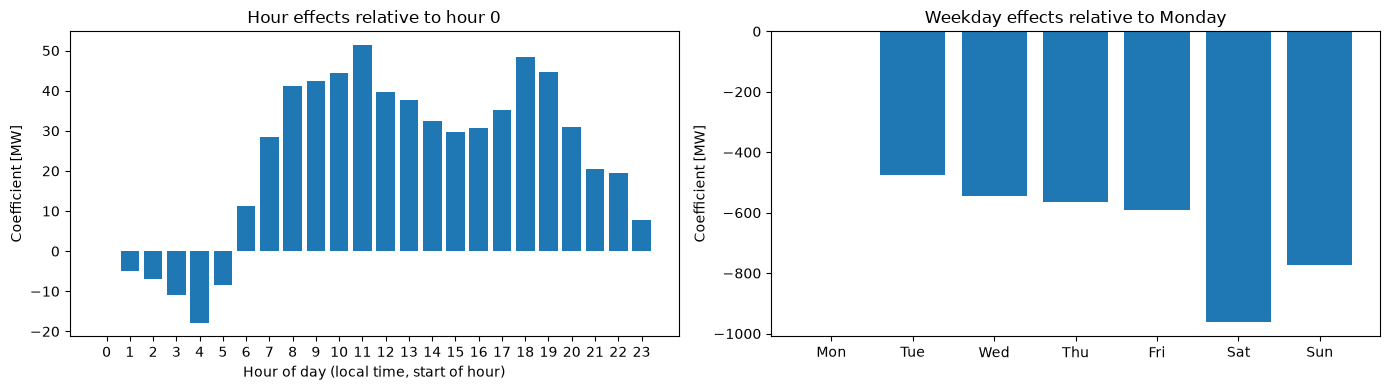

In [ ]:
# Plot the estimated coefficients of hat beta for features complementary to the above (hour and weekday effects)

# Hour coefficients gamma_1..gamma_23, with the reference hour 0 set to 0
hour_coef = pd.concat([pd.Series({0: 0.0}), coef.filter(like="hour_").set_axis(range(1, 24))])

# Weekday coefficients delta_1..delta_6, with the reference Monday set to 0
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_coef = pd.concat([pd.Series([0.0]), coef.filter(like="weekday_")]).set_axis(weekday_names)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(hour_coef.index, hour_coef.values)
axes[0].set_xticks(range(24))
axes[0].set_xlabel("Hour of day (local time, start of hour)")
axes[0].set_ylabel("Coefficient [MW]")
axes[0].set_title("Hour effects relative to hour 0")

axes[1].bar(weekday_coef.index, weekday_coef.values)
axes[1].set_ylabel("Coefficient [MW]")
axes[1].set_title("Weekday effects relative to Monday")

plt.tight_layout()
plt.show()

### How to read the coefficients

**The core of the forecast** is roughly the mean of the load on the previous day and one week earlier (weights 0.515 and 0.452, summing to about 0.97). Everything else is a correction on top of this mean.

**Holidays** (each multiplied by the holiday share of the respective day, between 0 and 1):
- If the forecast day itself is a holiday, the model subtracts about 900 MW.
- If the previous day was a holiday, it adds about 130 MW; if the day one week earlier was a holiday, it adds about 500 MW. These corrections make up for lag values that are too low because they come from a holiday.

The size of these effects is learned from 2020–2023; whether they apply is decided by the holiday calendar of the day concerned.

**Hours.** The bars are corrections relative to hour 0 (which is 0 by definition; its effect is part of the intercept). They follow the shape of the daily profile but are small (about −20 to 50 MW), because the lags already carry the daily pattern: a lag for 9 am is itself a 9 am value. The hour coefficients only fill in the small remainder.

**Weekdays.** The bars are corrections relative to Monday (0 by definition). All other days are negative because Monday needs the largest upward correction: its previous day is a Sunday, so `lag_24` is too low and the mean of the lags underestimates Monday. This upward correction is contained in the intercept. The other days need less of it (Tuesday–Friday, whose previous day is a weekday) or even a downward correction (Saturday, whose previous day is a busy Friday, and Sunday), so relative to Monday they are all negative.

**In general:** a coefficient is the effect of its feature *with all other features held fixed*. What the lags already explain does not appear again in the hour and weekday coefficients.

## Error analysis

To see where the regression outperforms the baseline, we compare their daily MAPE (Swiss local date) on the validation year, in particular whether the holiday peaks of the baseline are reduced.

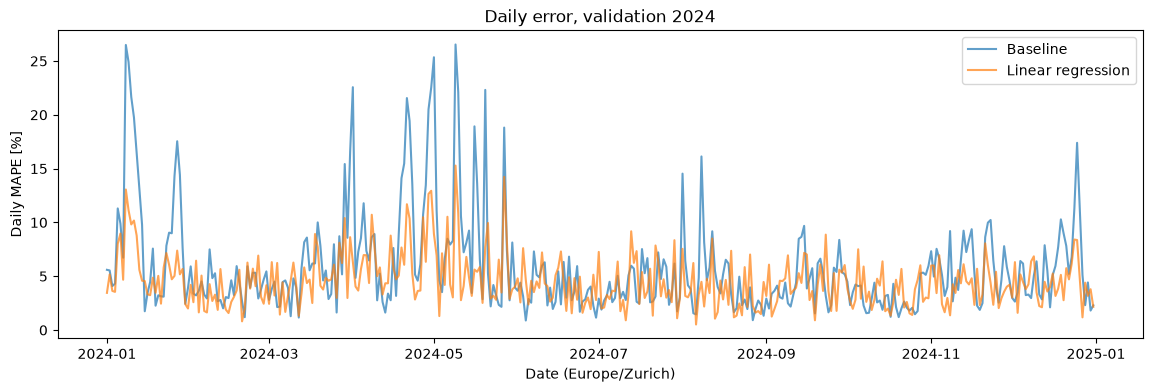

            baseline  linear
2024-05-09      26.5    15.3
2024-05-27      18.8    14.2
2024-01-08      26.5    13.1
2024-04-30      22.5    12.9
2024-04-29      20.5    12.6
2024-04-21      21.6    11.7
2024-01-09      24.9    11.1
2024-05-10      22.1    10.8
2024-04-08       8.6    10.7
2024-05-06       8.5    10.5
2024-04-27      10.7    10.5
2024-03-29      15.4    10.4
2024-04-22      19.4    10.4
2024-01-11      19.8    10.2
2024-05-21       5.3     9.9


In [15]:
# Local date of each validation hour (start of the hour)
day = (X_val.index - pd.Timedelta(hours=1)).tz_convert("Europe/Zurich").date

# Absolute percentage error per hour, averaged per day
ape_base = 100 * (y_val - y_hat_base).abs() / y_val
ape_lr = 100 * (y_val - y_hat_val).abs() / y_val
daily = pd.DataFrame({
    "baseline": ape_base.groupby(day).mean(),
    "linear": ape_lr.groupby(day).mean(),
})

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily["baseline"], label="Baseline", alpha=0.7)
ax.plot(daily.index, daily["linear"], label="Linear regression", alpha=0.7)
ax.set_xlabel("Date (Europe/Zurich)")
ax.set_ylabel("Daily MAPE [%]")
ax.set_title("Daily error, validation 2024")
ax.legend()
plt.show()

# The 15 days with the largest error of the linear regression
print(daily.sort_values("linear", ascending=False).head(15).round(1))

The linear regression has smaller and less volatile daily errors. Its largest errors still occur around holidays, but they are much reduced: Ascension (9 May) from 26.5 % to 15.3 %, the week after New Year from 20–27 % to 10–13 %, and the echo one week after Whit Monday from 18.8 % to 14.2 %.

On a few days the regression is worse than the baseline, e.g. 21 May (the Tuesday after Whit Monday): 5.3 % vs 9.9 %. Its previous day was a holiday, so `lag_24` is too low, but the learned correction (130 MW per unit holiday share) is much smaller than the actual shortfall. In the training years, days after holidays were often quiet themselves (St Stephen's Day, 2 January), so one coefficient cannot fit both cases. Bridge days such as 10 May remain difficult, as the model has no feature for them. Possible improvements: a bridge-day feature, and separate treatment of ordinary working days after a holiday.